
# Bank Account Fraud Detection
## Stage 1 – Dataset Study

### Research Question

What does performing well mean when approximately
99% of bank account applications are legitimate?

### Notebook Objective

This notebook documents the initial study of the
Bank Account Fraud (BAF) Base dataset.

The analysis follows the project documentation
and focuses on:

1. Understanding the dataset and its features.
2. Identifying the target variable.
3. Examining missing-value sentinel conventions.
4. Understanding class imbalance.
5. Preparing a chronological data split.
6. Identifying potential data leakage risks.

### Experimental Protocol

The project uses the following chronological split:

- Training: months 0–4
- Validation: month 5
- Held-out test: months 6–7

The held-out test period will not be inspected
or used during Stage 1 model development.

### Documentation Approach

Each analysis step will include:

- Objective
- Implementation
- Observed results
- Interpretation
- Limitations or open questions

All findings will be documented after running
the corresponding analysis.

### Reproducibility

The notebook will record the dataset version,
Python environment, preprocessing decisions,
and relevant experimental settings.



## 1. Official Dataset Documentation

### 1.1 Objective

Before performing any data analysis, we review the
official Bank Account Fraud (BAF) dataset documentation.

The purpose of this step is to understand:

- How the dataset was created.
- The meaning of the target variable.
- The temporal structure of the dataset.
- The categorical features.
- Missing-value conventions.
- Potential limitations and data leakage risks.

### 1.2 Dataset Overview

**Dataset name:** Bank Account Fraud (BAF) — Base variant

**Dataset type:** Synthetic bank account application data.

**Prediction task:** Binary classification.

The goal is to predict whether a bank account
application is fraudulent or legitimate.

The BAF dataset suite was developed for research
on fraud detection and related machine learning
challenges.

### 1.3 Target Variable

The target variable is `fraud_bool`.

- `0`: Legitimate application.
- `1`: Fraudulent application.

The dataset is highly imbalanced, with fraudulent
applications representing a small minority.

Therefore, classification accuracy alone may
provide a misleading evaluation of performance.

### 1.4 Temporal Feature

The dataset includes a feature named `month`,
representing the application month.

The available month values range from 0 to 7.

For this project, the chronological split is:

- **Training:** Months 0–4.
- **Validation:** Month 5.
- **Held-out test:** Months 6–7.

The held-out test period must not be inspected
during Stage 1 model development.

This split follows the project protocol.

### 1.5 Categorical Features

The dataset contains five categorical features:

1. `payment_type`
2. `employment_status`
3. `housing_status`
4. `source`
5. `device_os`

These features require appropriate encoding
before being used by machine learning models.

### 1.6 Missing-Value Conventions

Some numerical features use negative values,
such as `-1`, to indicate missing information.

Therefore, checking only for standard NaN
values is not sufficient.

Sentinel values must be identified and
interpreted before preprocessing.

### 1.7 Dataset Limitations

The dataset is synthetic rather than a direct
collection of real banking applications.

As a result, model performance on this dataset
may not fully generalize to real-world fraud
detection systems.

Potential data leakage must also be considered,
especially when using temporally ordered data.

### 1.8 Questions for Further Investigation

1. What is the exact fraud rate in training months 0–4?
2. Does the fraud rate change in validation month 5?
3. Which numerical features contain sentinel values?
4. Are there features that could introduce data leakage?
5. How should categorical variables be encoded?
6. Which evaluation metrics are appropriate for
   highly imbalanced fraud detection?

### 1.9 References

Official BAF Dataset Datasheet:

https://raw.githubusercontent.com/feedzai/bank-account-fraud/main/documents/datasheet.pdf

Project Dataset Study:

https://github.com/fidaaarrabi/ml-project-bank-fraud-detection/blob/main/docs/dataset_study.md

### 1.10 Conclusion

The BAF Base dataset presents a binary
classification problem with severe class imbalance.

Understanding the dataset documentation,
missing-value conventions, and chronological
structure is essential before developing
fraud detection models.

The next step is to load the dataset and
verify its structure using Python.


In [2]:

# =====================================================
# 2. Environment Setup and Reproducibility
# =====================================================

import sys
import pandas as pd
import numpy as np
import sklearn

print("=== ENVIRONMENT INFORMATION ===")
print(f"Python version: {sys.version.split()[0]}")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")


=== ENVIRONMENT INFORMATION ===
Python version: 3.12.10
Pandas version: 3.1.1
NumPy version: 2.5.5
Scikit-learn version: 1.9.1



## 3. Dataset Loading

### Objective

Load the BAF Base dataset for Stage 1 analysis
while respecting the chronological data protocol.

### Chronological Split

- Training: months 0–4.
- Validation: month 5.
- Held-out test: months 6–7.

Only observations from months 0–5 will be
retained for Stage 1 analysis.

### Data Storage

The dataset is stored locally at
`data/raw/Base.csv`.

Raw data files are excluded from Git version
control using the `.gitignore` file.


In [3]:

# =====================================================
# 3.1 Dataset Loading
# =====================================================

from pathlib import Path

# Define the dataset path
data_path = Path("../data/raw/Base.csv")

# Support execution from the project root
if not data_path.is_file():
    data_path = Path("data/raw/Base.csv")

# Verify that the dataset exists
assert data_path.is_file(), "Dataset file not found."

# Load and retain only months 0–5
df = pd.concat(
    (
        chunk.loc[chunk["month"].between(0, 5)]
        for chunk in pd.read_csv(
            data_path,
            chunksize=100_000
        )
    ),
    ignore_index=True
)

# Verify that only Stage 1 months are retained
assert not df.empty, "No observations were loaded."
assert df["month"].between(0, 5).all()

# Display loading results
print("=== DATASET LOADING ===")
print("Dataset loaded successfully.")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")
print(f"Available months: {sorted(df['month'].unique().tolist())}")


=== DATASET LOADING ===
Dataset loaded successfully.
Number of rows: 794,989
Number of columns: 32
Available months: [0, 1, 2, 3, 4, 5]



### 3.2 Loading Results and Interpretation

The dataset was successfully loaded and restricted
to the Stage 1 period.

The resulting dataset contains 794,989 observations
and 32 columns.

Only months 0–5 are retained, confirming that
the held-out test months 6–7 are excluded
from the working dataset.

This restriction helps prevent information leakage
from the held-out test period during model development.



## 4. Dataset Shape and Types

### Objective

Examine the structure of the Stage 1 dataset,
identify the target variable, and distinguish
between numerical and categorical features.

This step provides the foundation for subsequent
data analysis and preprocessing decisions.


In [4]:

# =====================================================
# 4.1 Dataset Structure and Feature Types
# =====================================================

# Display dataset dimensions
print("=== DATASET SHAPE ===")
print(f"Number of observations: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

# Display column names and data types
print("\n=== COLUMN NAMES AND DATA TYPES ===")
print(df.dtypes)

# Define the target variable
target_column = "fraud_bool"

# Verify that the target exists
assert target_column in df.columns, "Target column not found."

# Separate predictors from the target
features = df.drop(columns=[target_column])

# Identify numerical features
numerical_features = features.select_dtypes(
    include="number"
).columns.tolist()

# Identify categorical features
categorical_features = features.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Display feature summary
print("\n=== FEATURE SUMMARY ===")
print(f"Target variable: {target_column}")
print(f"Total features: {features.shape[1]}")
print(f"Numerical features: {len(numerical_features)}")
print(f"Categorical features: {len(categorical_features)}")

print("\n=== NUMERICAL FEATURES ===")
print(numerical_features)

print("\n=== CATEGORICAL FEATURES ===")
print(categorical_features)


=== DATASET SHAPE ===
Number of observations: 794,989
Number of columns: 32

=== COLUMN NAMES AND DATA TYPES ===
fraud_bool                            int64
income                              float64
name_email_similarity               float64
prev_address_months_count             int64
current_address_months_count          int64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                            str
zip_count_4w                          int64
velocity_6h                         float64
velocity_24h                        float64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                       str
credit_risk_score                     int64
email_is_free                         int64
housing_status                          str
phone_home_valid                      int64
phone_m


### 4.2 Dataset Structure — Findings and Interpretation

The Stage 1 dataset contains 794,989 observations
and 32 columns, including the target variable
`fraud_bool`.

The 31 non-target columns consist of:

- 26 numerical features.
- 5 categorical features.

The identified categorical features are consistent
with the official dataset documentation.

### Implications for Preprocessing

- Categorical features require appropriate encoding
  before logistic regression can be applied.
- Numerical features may require scaling depending
  on their meaning and distribution.
- Binary indicators should be distinguished from
  continuous numerical features.
- The `month` column is used for chronological
  splitting and should be evaluated separately
  from the predictive features.

### Conclusion

The dataset structure was successfully verified.

No feature encoding, scaling, feature removal,
or model training has been performed at this stage.

The next step is to examine the target distribution
in the training period and validation month.



## 5. Target Distribution — Training Period

### Objective

Analyze the distribution of the target variable
`fraud_bool` within the training period
(months 0–4).

The purpose is to quantify class imbalance
and understand its implications for fraud
detection and model evaluation.

### Research Questions

- How many legitimate applications are present?
- How many fraudulent applications are present?
- What is the fraud prevalence?
- How severe is the class imbalance?
- Why might accuracy be misleading?

### Expected Findings

Based on the dataset documentation, we expect
fraudulent applications to represent approximately
1% of the training observations.

Therefore, we expect a highly imbalanced
classification problem.


In [5]:

# =====================================================
# 5.1 Chronological Train-Validation Split
# =====================================================

# Training data: months 0–4
train_df = df.loc[df["month"].between(0, 4)].copy()

# Validation data: month 5
val_df = df.loc[df["month"] == 5].copy()

# Verify chronological separation
assert not train_df.empty
assert not val_df.empty

assert train_df["month"].max() < val_df["month"].min()

# Verify that all Stage 1 observations are included
assert len(train_df) + len(val_df) == len(df)

# Display split information
print("=== CHRONOLOGICAL SPLIT ===")

print("\nTraining set:")
print(f"Observations: {len(train_df):,}")
print(f"Months: {sorted(train_df['month'].unique().tolist())}")
print(f"Percentage: {len(train_df) / len(df) * 100:.2f}%")

print("\nValidation set:")
print(f"Observations: {len(val_df):,}")
print(f"Months: {sorted(val_df['month'].unique().tolist())}")
print(f"Percentage: {len(val_df) / len(df) * 100:.2f}%")


=== CHRONOLOGICAL SPLIT ===

Training set:
Observations: 675,666
Months: [0, 1, 2, 3, 4]
Percentage: 84.99%

Validation set:
Observations: 119,323
Months: [5]
Percentage: 15.01%


In [6]:

# =====================================================
# 5.2 Training Target Distribution
# =====================================================

# Verify that the target contains only binary values
assert train_df["fraud_bool"].isin([0, 1]).all()

# Count observations in each class
class_counts = train_df["fraud_bool"].value_counts()

legitimate_count = class_counts.get(0, 0)
fraud_count = class_counts.get(1, 0)

total_count = len(train_df)

# Calculate class percentages
legitimate_percentage = legitimate_count / total_count * 100
fraud_percentage = fraud_count / total_count * 100

# Calculate the imbalance ratio
imbalance_ratio = legitimate_count / fraud_count

# Display results
print("=== TRAINING TARGET DISTRIBUTION ===")

print(f"Total applications: {total_count:,}")

print("\nLegitimate applications (Class 0):")
print(f"Count: {legitimate_count:,}")
print(f"Percentage: {legitimate_percentage:.4f}%")

print("\nFraudulent applications (Class 1):")
print(f"Count: {fraud_count:,}")
print(f"Percentage: {fraud_percentage:.4f}%")

print("\n=== CLASS IMBALANCE ===")
print(f"Fraud prevalence: {fraud_percentage:.4f}%")
print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")


=== TRAINING TARGET DISTRIBUTION ===
Total applications: 675,666

Legitimate applications (Class 0):
Count: 668,926
Percentage: 99.0025%

Fraudulent applications (Class 1):
Count: 6,740
Percentage: 0.9975%

=== CLASS IMBALANCE ===
Fraud prevalence: 0.9975%
Imbalance ratio: 99.25:1


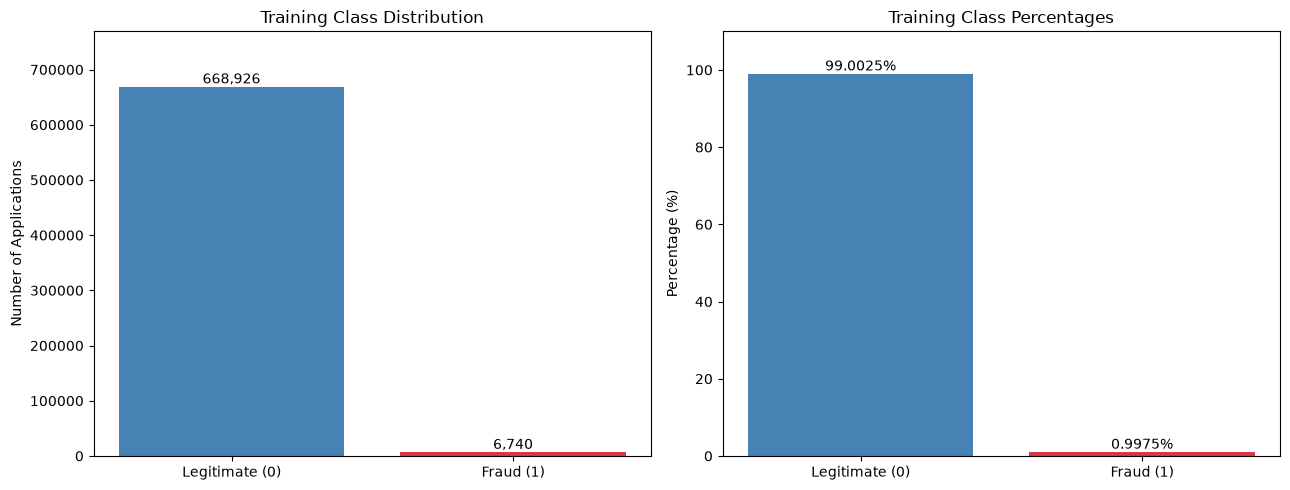

In [7]:

# =====================================================
# 5.3 Class Distribution Visualization
# =====================================================

import matplotlib.pyplot as plt

labels = ["Legitimate (0)", "Fraud (1)"]

counts = [legitimate_count, fraud_count]

percentages = [
    legitimate_percentage,
    fraud_percentage
]

colors = ["#4682B4", "#DC3545"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot absolute class counts
bars = axes[0].bar(labels, counts, color=colors)

axes[0].set_title("Training Class Distribution")
axes[0].set_ylabel("Number of Applications")
axes[0].set_ylim(0, max(counts) * 1.15)

for bar, count in zip(bars, counts):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom"
    )

# Plot relative class frequencies
bars = axes[1].bar(labels, percentages, color=colors)

axes[1].set_title("Training Class Percentages")
axes[1].set_ylabel("Percentage (%)")
axes[1].set_ylim(0, 110)

for bar, percentage in zip(bars, percentages):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage:.4f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()



### 5.4 Training Target Distribution — Findings

The training set contains 675,666 applications:

- Legitimate applications: 668,926 (99.0025%).
- Fraudulent applications: 6,740 (0.9975%).

The class imbalance ratio is approximately 99.25:1,
indicating a severely imbalanced classification problem.

### Expected vs. Observed Results

Before the analysis, we expected fraudulent
applications to represent approximately 1%
of the training data.

The observed fraud prevalence of 0.9975%
is consistent with this expectation.

### Implications for Model Evaluation

A classifier that always predicts the majority
class could achieve approximately 99% accuracy
without detecting any fraudulent applications.

Therefore, accuracy alone is insufficient
for evaluating fraud detection models.

Additional evaluation metrics will be required,
including precision, recall, and Average Precision.



## 6. Majority Class Baseline

### Objective

Evaluate a naive classifier that predicts every
application as legitimate, regardless of its features.

This baseline demonstrates the limitations of
accuracy under severe class imbalance.

### Hypothesis Before the Experiment

We expect the majority class classifier to achieve:

- Accuracy of approximately 99%.
- Fraud recall of 0%.
- Fraud precision of 0%, using a zero-division convention.
- F1-score of 0%.

Despite its high expected accuracy, the classifier
will have no practical ability to detect fraud.

The experiment will demonstrate why high accuracy
does not necessarily indicate good fraud detection
performance.


In [8]:

# =====================================================
# 6.1 Majority Class Baseline Experiment
# =====================================================

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# Extract the training target
y_train = train_df["fraud_bool"]

# Create placeholder features
X_dummy_train = np.zeros((len(y_train), 1))

# Initialize the majority class classifier
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

# Fit the baseline model
dummy_model.fit(X_dummy_train, y_train)

# Generate class predictions
y_dummy_pred = dummy_model.predict(X_dummy_train)

# Generate fraud probability scores
y_dummy_scores = dummy_model.predict_proba(
    X_dummy_train
)[:, 1]

# Calculate evaluation metrics
dummy_accuracy = accuracy_score(y_train, y_dummy_pred)

dummy_precision = precision_score(
    y_train, y_dummy_pred, zero_division=0
)

dummy_recall = recall_score(
    y_train, y_dummy_pred, zero_division=0
)

dummy_f1 = f1_score(
    y_train, y_dummy_pred, zero_division=0
)

dummy_ap = average_precision_score(
    y_train, y_dummy_scores
)

# Display evaluation results
print("=== MAJORITY CLASS BASELINE ===")

print(f"Accuracy:          {dummy_accuracy:.6f}")
print(f"Precision:         {dummy_precision:.6f}")
print(f"Recall:            {dummy_recall:.6f}")
print(f"F1-score:          {dummy_f1:.6f}")
print(f"Average Precision: {dummy_ap:.6f}")

print("\n=== CONFUSION MATRIX ===")
print(confusion_matrix(y_train, y_dummy_pred, labels=[0, 1]))


=== MAJORITY CLASS BASELINE ===
Accuracy:          0.990025
Precision:         0.000000
Recall:            0.000000
F1-score:          0.000000
Average Precision: 0.009975

=== CONFUSION MATRIX ===
[[668926      0]
 [  6740      0]]


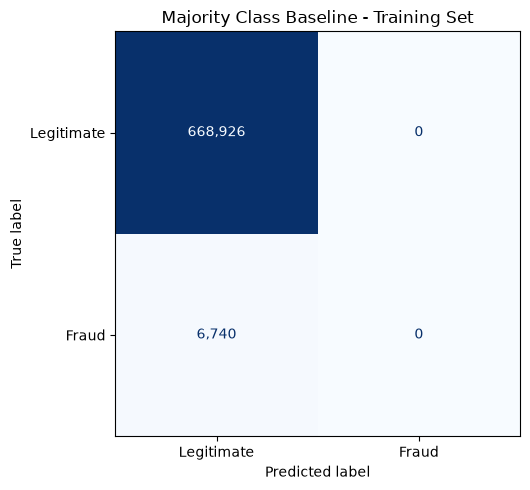

In [9]:

# =====================================================
# 6.2 Majority Class Baseline - Confusion Matrix
# =====================================================

from sklearn.metrics import ConfusionMatrixDisplay

# Calculate the confusion matrix
dummy_cm = confusion_matrix(
    y_train,
    y_dummy_pred,
    labels=[0, 1]
)

# Create the visualization
fig, ax = plt.subplots(figsize=(7, 5))

display = ConfusionMatrixDisplay(
    confusion_matrix=dummy_cm,
    display_labels=["Legitimate", "Fraud"]
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format=",d",
    colorbar=False
)

ax.set_title("Majority Class Baseline - Training Set")

plt.tight_layout()
plt.show()



### 6.3 Majority Class Baseline — Findings

The majority class classifier was evaluated
on the training period (months 0–4).

#### Experimental Results

| Metric | Result |
|---|---:|
| Accuracy | 0.990025 |
| Precision | 0.000000 |
| Recall | 0.000000 |
| F1-score | 0.000000 |
| Average Precision | 0.009975 |

#### Confusion Matrix Interpretation

- True Negatives: 668,926
- False Positives: 0
- False Negatives: 6,740
- True Positives: 0

The classifier correctly identifies all legitimate
applications but fails to detect any fraudulent
applications.

Precision is undefined because no positive
predictions are made. It is reported as zero
using the zero-division convention.

#### Expected vs. Observed Results

The experimental results support our initial
hypothesis.

Despite achieving approximately 99% accuracy,
the classifier has zero fraud recall and
provides no useful fraud detection capability.

#### Average Precision Interpretation

The classifier assigns identical fraud scores
to all applications.

Therefore, its Average Precision equals the
fraud prevalence of the evaluated dataset.

This provides a no-discrimination reference
for evaluating future models.

#### Limitations

This experiment was conducted on the training
data for demonstration purposes.

A fair comparison between predictive models
will require evaluation on the same validation
period using consistent evaluation metrics.

#### Conclusion

Accuracy alone is not an appropriate evaluation
criterion for severely imbalanced fraud detection.

Precision, recall, Average Precision, and
Precision-Recall curves should be considered
when evaluating future models.
